# VL-JEPA: medical question answering by predicting embeddings

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/vqa/vljepa.ipynb)

[VL-JEPA](https://arxiv.org/abs/2512.10942) predicts the *embedding* of the answer from visual tokens and a question, so it never generates tokens during training. Text comes out only on demand, here by retrieval over every answer the questions can have.

The data is medical VQA in the style of the [MMBU challenge](https://akiranishii.github.io/mmbu-challenge/), built from [MedMNIST v2](https://medmnist.com): blood-cell microscopy, dermatoscopy and breast ultrasound.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, WeightedRandomSampler

from torch_world import evaluation, plots
from torch_world.datasets import MedicalVQA
from torch_world.models import VLJEPA
from torch_world.nn import PatchTokens, TextEncoder, Transformer, WordTokenizer

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## 1. Data
`MedicalVQA` downloads the MedMNIST files once (CC BY 4.0, MD5-checked) and asks up to four kinds of question about every image: the imaging **modality**, the **finding**, a **verification** of a named finding (true half of the time) and **malignancy**. Every item also carries a caption of its image.

dataset      modality                 classes  images      modality       finding  verification    malignancy
bloodmnist   blood smear microscopy         8   11959         11959         11959         11959             0
dermamnist   dermatoscopy                   7    7007          7007          7007          7007          7007
breastmnist  breast ultrasound              2     546           546             0             0           546
19512 images and 64997 questions (train)


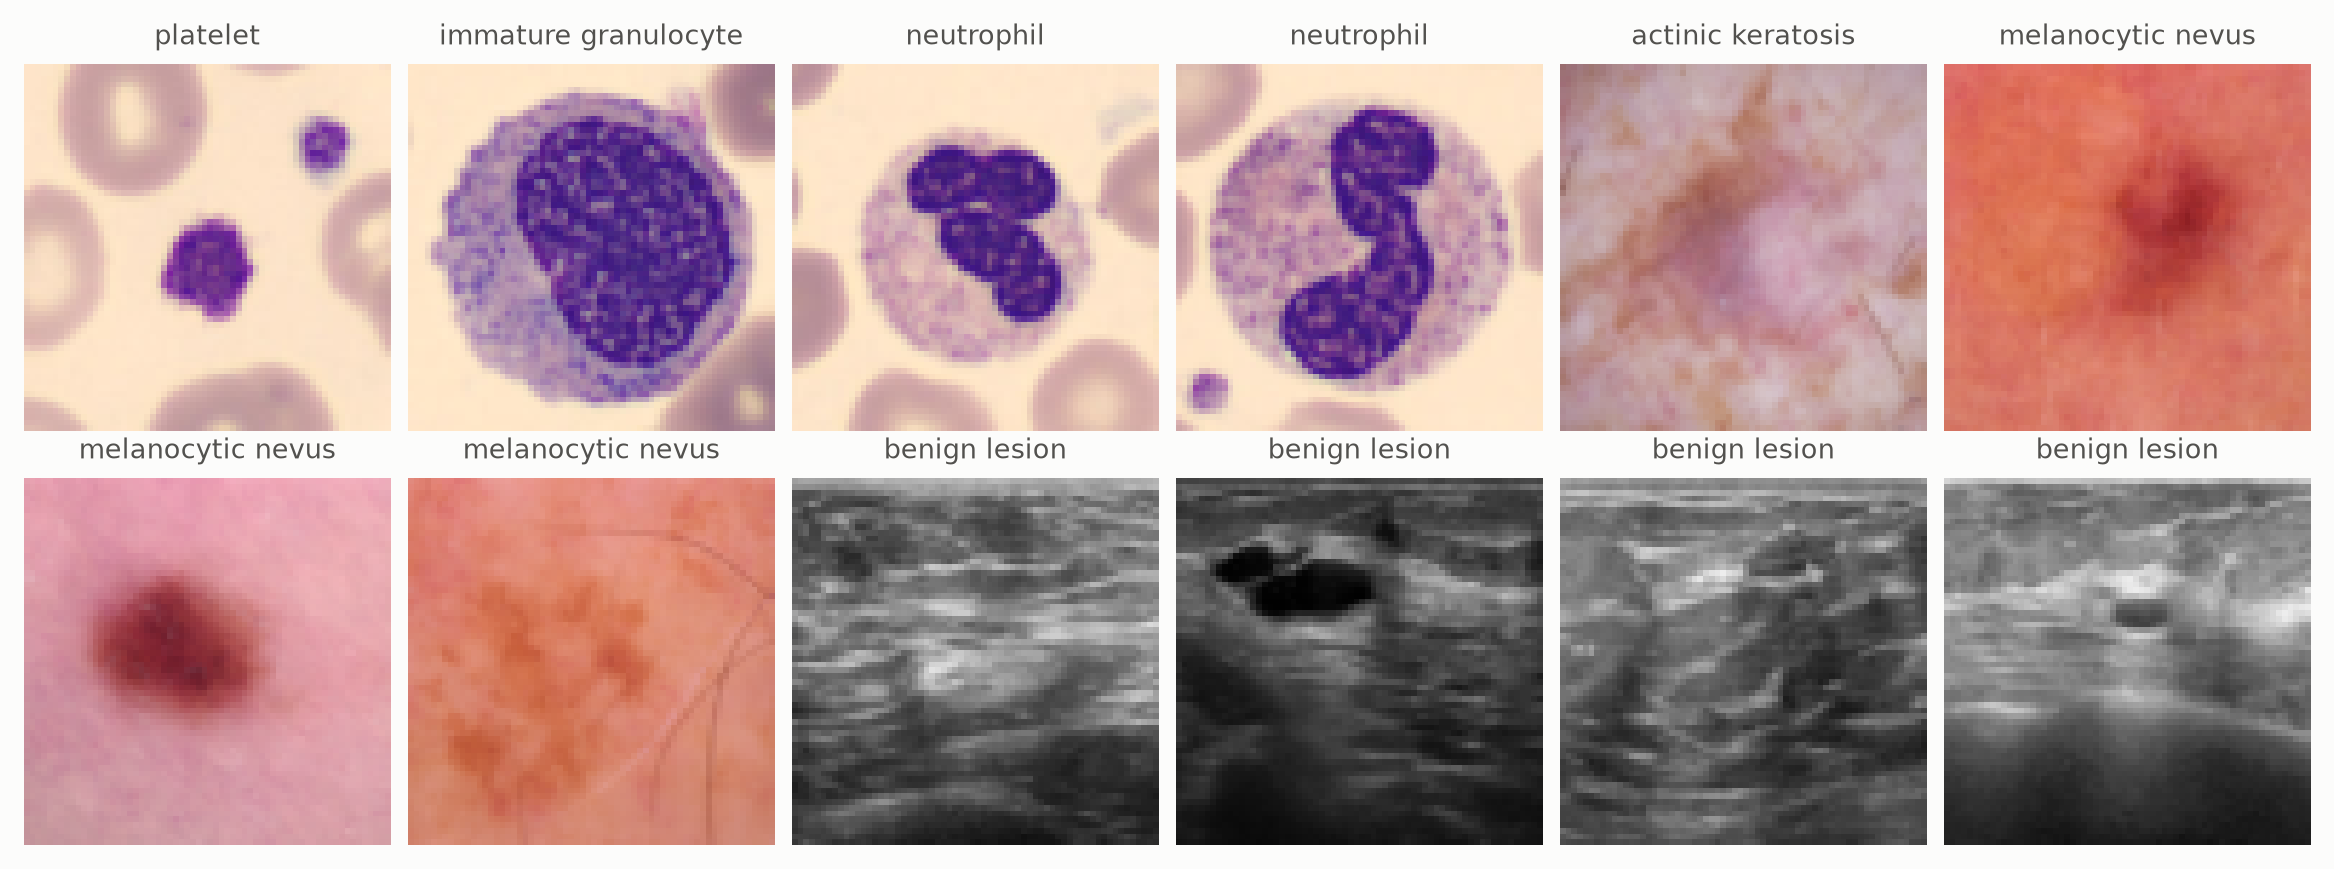

In [2]:
DATASETS = ["bloodmnist", "dermamnist", "breastmnist"]
train, test = MedicalVQA(DATASETS, "train"), MedicalVQA(DATASETS, "test", seed=1)
print(train.info)
plots.images(*train.examples(4), ncols=6, size=1.6)

In [3]:
for i in range(3):
    print(f"{train[i]['question']:34s} {train[i]['answer']}")
print(f"{'caption':34s} {train[0]['caption']}")

what imaging modality is this ?    blood smear microscopy
what finding is shown ?            platelet
is this a neutrophil ?             no
caption                            blood smear microscopy showing a platelet


## 2. Encode the images once
The X-encoder is frozen (a V-JEPA 2 ViT-L in the paper; DINOv2 ViT-S/14 at 112 px here, 8×8 patch tokens). `encode` caches its tokens inside the datasets, so training touches only the predictor and the Y-encoder.

In [4]:
encoder = PatchTokens.from_hub("dinov2_vits14", size=112).to(device)
train.encode(encoder)
test.encode(encoder)
print("cached tokens", tuple(train.features.shape))

cached tokens (19512, 64, 384)


## 3. Model
The predictor reads the visual tokens followed by the question (the last 8 layers of Llama-3.2-1B in the paper). The Y-encoder embeds the answer (EmbeddingGemma in the paper) and trains at 0.1× the learning rate. Small stand-ins keep the same interfaces; `WordTokenizer` turns the dataset's closed vocabulary into token ids for them.

In [5]:
tokenizer = WordTokenizer(train.texts, device=device)
model = VLJEPA(
    x_encoder=nn.Identity(),
    predictor=Transformer(256, depth=4, num_heads=8),
    query_embed=nn.Embedding(len(tokenizer), 256),
    y_encoder=TextEncoder(len(tokenizer), dim=128),
    vision_dim=384, predictor_dim=256, text_dim=128, embed_dim=128, y_lr_mult=0.1,
).to(device)
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M trainable parameters, {len(tokenizer)} words")

3.72M trainable parameters, 43 words


## 4. Train
Batches give the three datasets equal weight. The first 1000 steps align images with their captions (no query); after that, questions are mixed with one caption batch in three, so query-free prediction is kept.

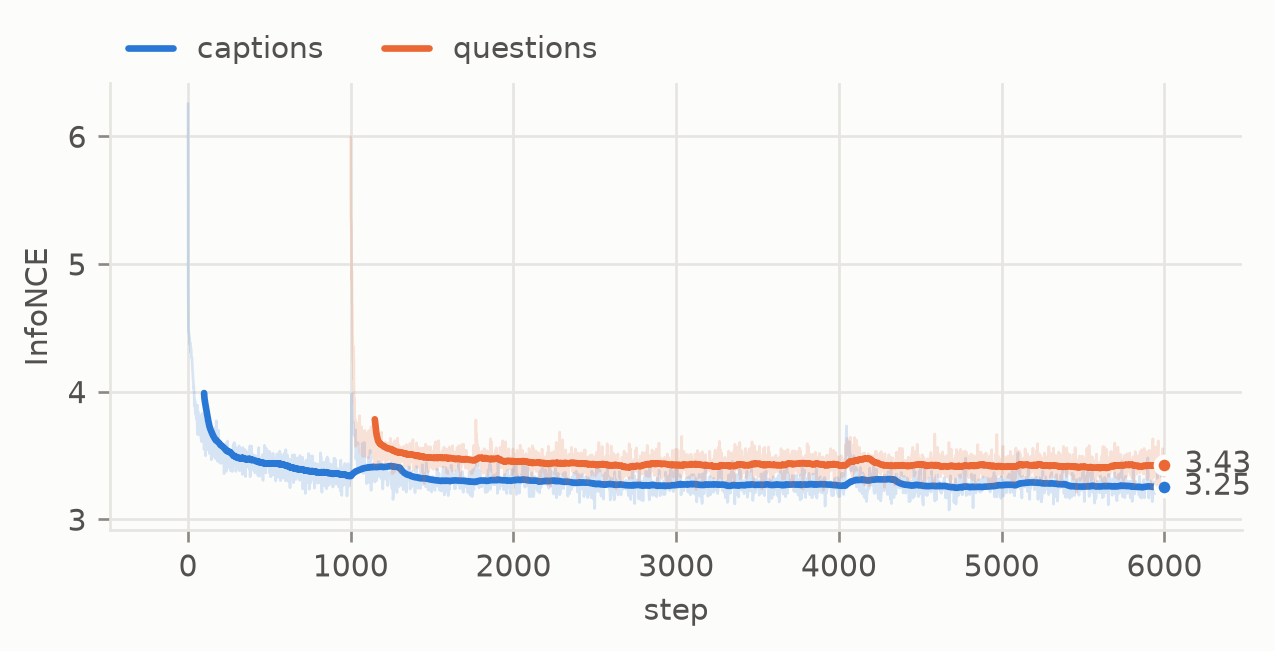

In [6]:
STEPS = 6000
loader = DataLoader(train, batch_size=256, sampler=WeightedRandomSampler(train.weights(), STEPS * 256))
opt = torch.optim.AdamW(model.param_groups(3e-4, weight_decay=0.01))
log = {"captions": ([], []), "questions": ([], [])}
for step, batch in enumerate(loader):
    x = batch["image"].float()
    if step < 1000 or step % 3 == 0:
        kind, loss = "captions", model(x, *tokenizer(batch["caption"]))["loss"]
    else:
        kind, loss = "questions", model(x, *tokenizer(batch["answer"]), *tokenizer(batch["question"]))["loss"]
    opt.zero_grad()
    loss.backward()
    opt.step()
    log[kind][0].append(step)
    log[kind][1].append(loss.item())
plots.curves(log, logy=False, ylabel="InfoNCE", smooth=100)

## 5. Evaluate
`evaluation.vqa` answers every test question by retrieval over all possible answers and scores each kind against always giving its most common answer.

kind            accuracy  majority  questions
modality           1.000     0.613       5582
finding            0.887     0.247       5426
verification       0.944     0.576       5426
malignancy         0.842     0.799       2161
all                0.932                18595


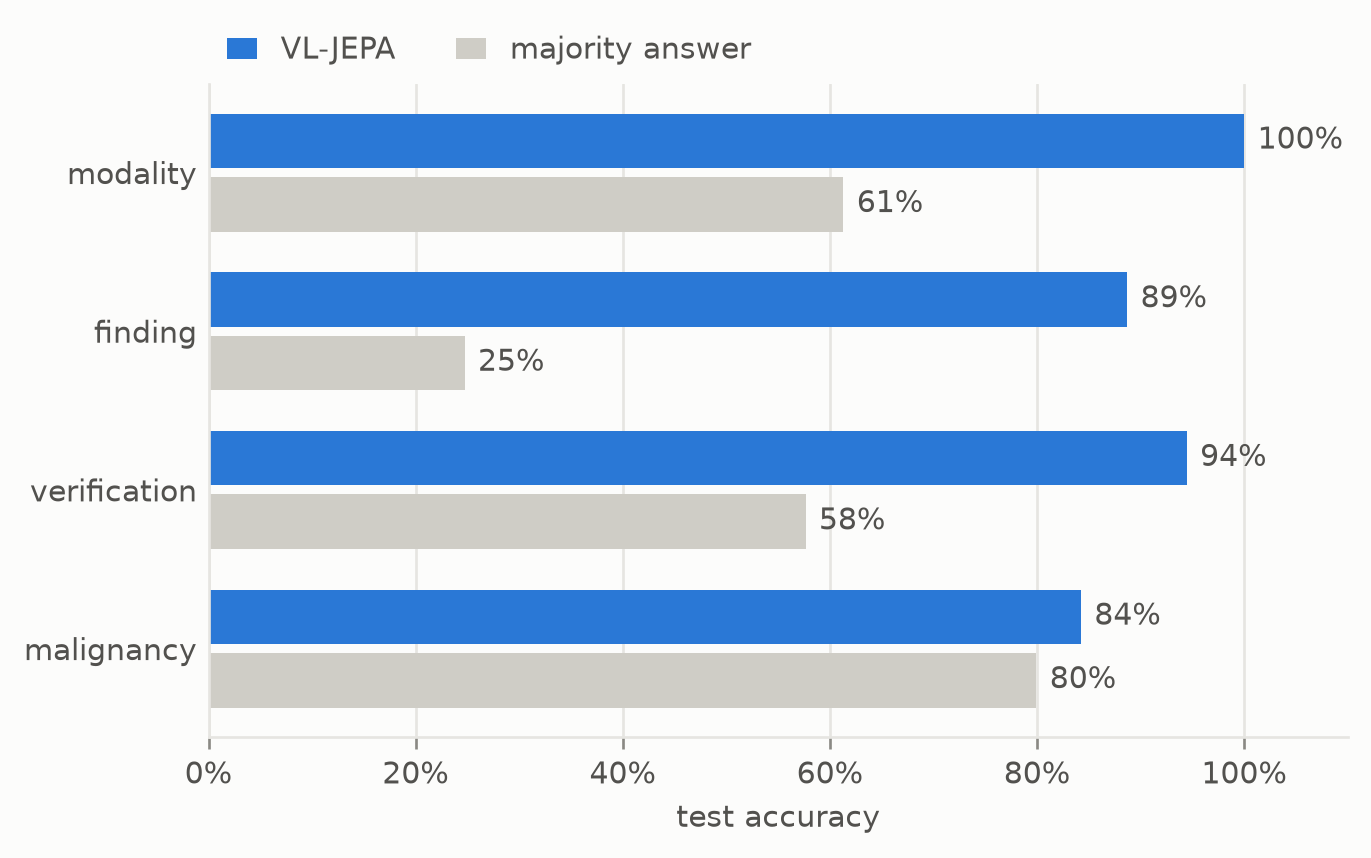

In [7]:
results = evaluation.vqa(model.eval(), test, tokenizer)
print(results)
plots.bars(results.scores("VL-JEPA"), xlabel="test accuracy", baseline="majority answer")

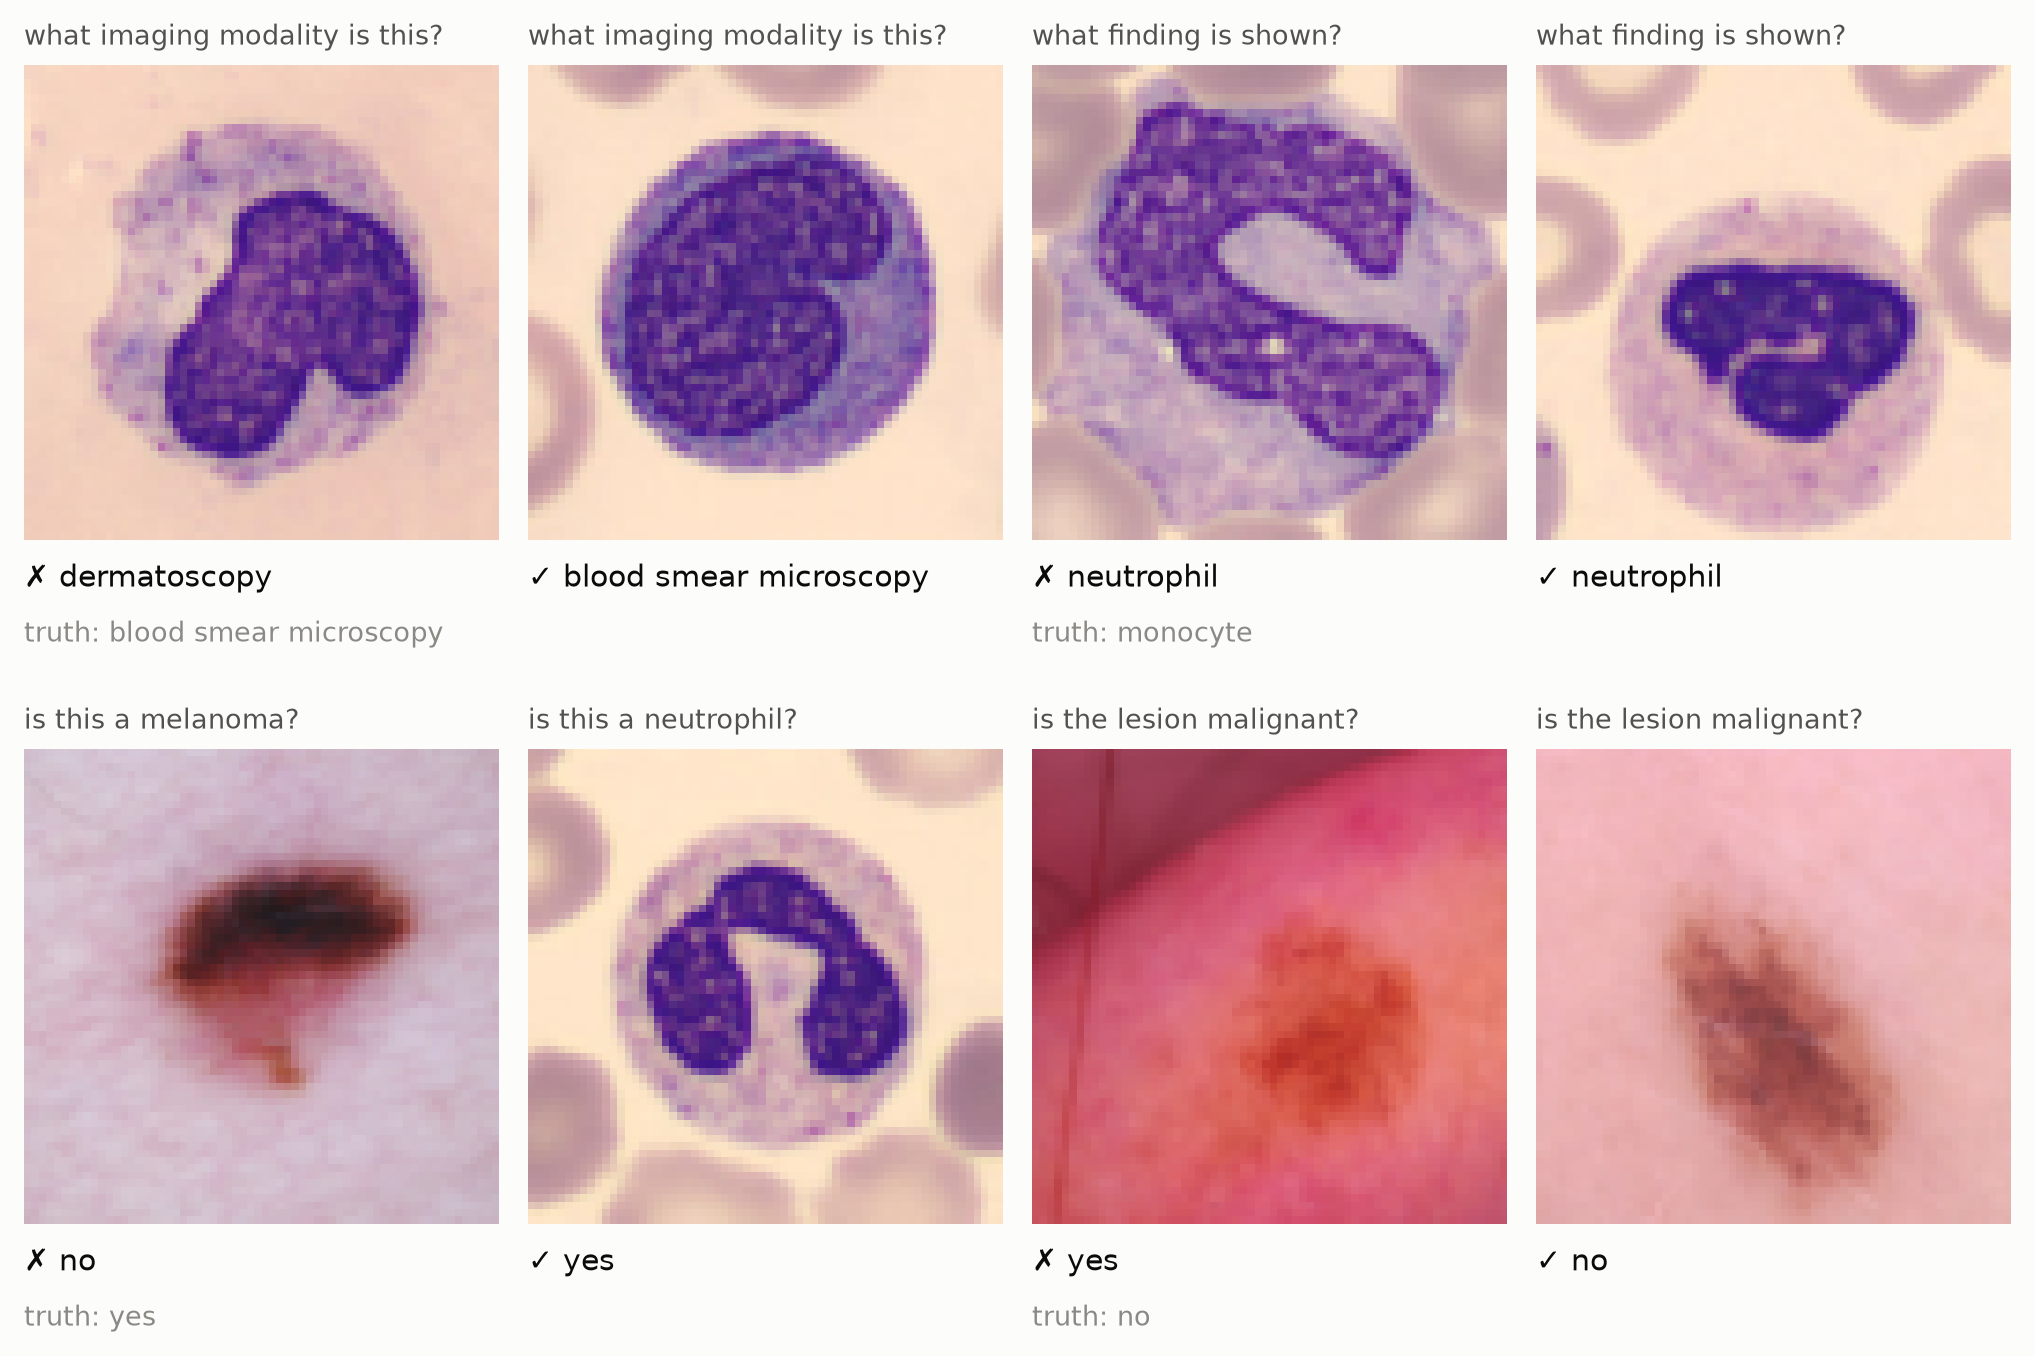

In [8]:
plots.answers(*results.cards(per_kind=2))

## 6. Is it overfitting?
Perfect modality accuracy deserves a check. Three controls:
- **train vs test**: a model that memorized its training images would score far higher on them than on new ones.
- **shuffled images**: every test question is asked about a random test image. Accuracy that survives this comes from the question alone, not from the image.
- **majority answer**: what always giving the most common answer scores.

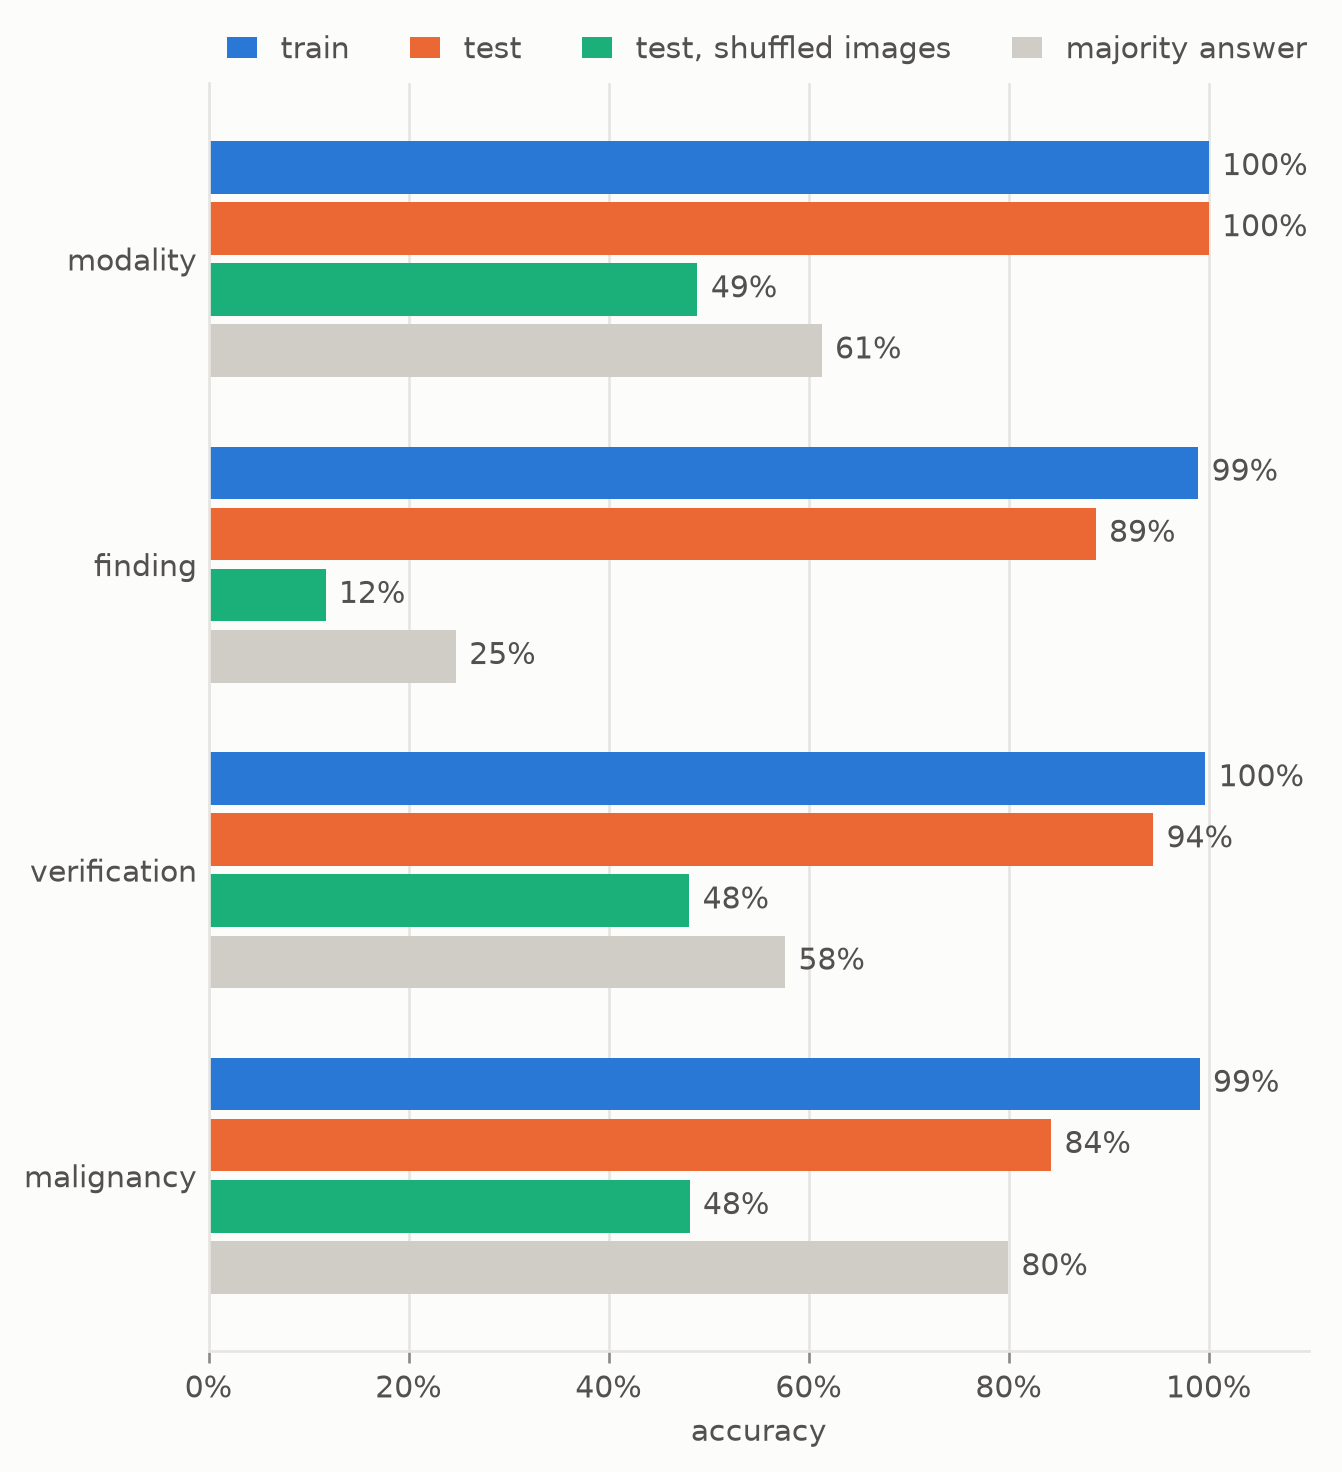

In [9]:
checks = {
    "train": evaluation.vqa(model, train, tokenizer),
    "test": results,
    "test, shuffled images": evaluation.vqa(model, test, tokenizer, shuffle_images=True, generator=torch.Generator().manual_seed(0)),
}
plots.bars(evaluation.compare(checks), baseline="majority answer")

**Modality is genuinely easy, not memorized.** Blood smears, dermatoscopy and breast ultrasound look nothing alike, so 100% holds on unseen test images. With shuffled images, modality falls to about the chance that a random image shares the right modality, so the answer comes from the image, not from the question.

**Fine-grained answers show a real generalization gap.** Finding and malignancy are near-perfect on train and lower on test: the small predictor memorizes some training images, as expected from about 20k training images. Their shuffled-image scores fall below the majority answer, so what the model knows comes from looking. Malignancy remains the hardest kind, only modestly above always answering "no".

For a fair score, select checkpoints on the `"val"` split (`MedicalVQA(DATASETS, "val")`) and touch the test split once.

## Your own data and models

**Other MedMNIST data.** `MedicalVQA` also covers `pathmnist` (colon pathology) and `organamnist` (abdominal CT), at 28, 64, 128 or 224 px:

```python
train = MedicalVQA(["pathmnist", "organamnist"], "train", size=128)
```

**Your own dataset.** Any dataset whose items hold `image`, `question`, `answer` and `kind` can be trained and evaluated the same way. Give it `answers` (the candidates for retrieval) and `pixels(items)` (images for `plots.answers`):

```python
class RadiologyVQA(torch.utils.data.Dataset):
    def __init__(self, images, rows):          # rows: [(image index, kind, question, answer), ...]
        self.images, self.rows = images, rows
        self.answers = sorted({a for *_, a in rows})

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        image, kind, question, answer = self.rows[i]
        return {"image": self.images[image], "question": question, "answer": answer, "kind": kind}

    def pixels(self, items):
        return self.images[[self.rows[i][0] for i in items]]
```

**Your own model parts.** Each part is a plain module, so stronger ones drop in:
- X-encoder: any frozen module from images to tokens `(B, N, vision_dim)`, e.g. `PatchTokens.from_hub("dinov2_vitb14", size=224)` with `vision_dim=768`.
- Predictor: any module mapping `(tokens, attn_mask=...)` to tokens, e.g. a deeper `Transformer` or the last layers of a language model.
- Y-encoder: any module mapping `(ids, mask)` to `(B, text_dim)`, with its own tokenizer in place of `WordTokenizer`.